# TimePFN LMC-Synth — séries latentes versus previsões AR

Este notebook avalia o caminho **oracle latent AR**: cada uma das três séries latentes de cada mecanismo é comparada com sua previsão AR de um passo à frente. Cada série usa individualmente a ordem AR com menor NMSE. A divisão é exclusivamente `deu certo` quando `NMSE <= 0.001` e `deu errado` quando `NMSE > 0.001`. O caminho VAR multivariado não é incluído porque a solicitação é especificamente sobre modelos AR.

In [1]:
from __future__ import annotations

from pathlib import Path
import hashlib
import importlib.metadata
import json
import math
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').exists() and (candidate / 'experiments').exists():
            return candidate
    raise RuntimeError('Repository root not found')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SOURCE_NOTEBOOK = PROJECT_ROOT / 'experiments' / 'autoregressive_process_coverage' / 'AR' / '02_timepfn_lmc_ar_var_coverage.ipynb'
PLOT_POINTS = 320
NMSE_THRESHOLD = 0.001

def notebook_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding='utf-8'))

def embedded_record(notebook: dict) -> dict:
    for cell in reversed(notebook['cells']):
        for output in cell.get('outputs', []):
            text = ''.join(output.get('text', []))
            if 'COMPLETE EXPERIMENT RECORD' in text and '{' in text:
                return json.loads(text[text.index('{'):])
    raise RuntimeError('Canonical experiment record not found')

source_nb = notebook_json(SOURCE_NOTEBOOK)
canonical_record = embedded_record(source_nb)
# Reuse the exact configuration, latent generators, AR implementation, and LMC bank from the source experiment.
for cell_index in (1, 3):
    source = ''.join(source_nb['cells'][cell_index]['source'])
    exec(compile(source, f'{SOURCE_NOTEBOOK}#cell-{cell_index}', 'exec'), globals())

print(f'Fonte canônica: {SOURCE_NOTEBOOK.relative_to(PROJECT_ROOT)}')
print(f'Mecanismos LMC: {len(LMC_MECHANISMS)} | séries latentes: {3 * len(LMC_MECHANISMS)} | ordens: {ORDERS}')

,id,latent_ids,dirichlet_alpha
0,lmc_01,"[periodic_01_p24, periodic_02_p48, periodic_03...",0.2
1,lmc_02,"[periodic_04_p168, periodic_05_p336, periodic_...",0.5
2,lmc_03,"[periodic_07_p7, periodic_08_p14, periodic_09_...",1.0
3,lmc_04,"[periodic_10_p60, periodic_11_p365, periodic_1...",2.0
4,lmc_05,"[periodic_13_p4, periodic_14_p26, periodic_15_...",0.2
5,lmc_06,"[periodic_16_p4, periodic_17_p6, periodic_18_p12]",0.5
6,lmc_07,"[periodic_19_p4, periodic_20_p40, periodic_21_...",1.0
7,lmc_08,"[linear_sigma0, linear_sigma1, linear_sigma10]",2.0
8,lmc_09,"[rbf_scale0.1, rbf_scale1, rbf_scale10]",0.2
9,lmc_10,"[rq_alpha0.1, rq_alpha1, rq_alpha10]",0.5


Fonte canônica: experiments\autoregressive_process_coverage\AR\02_timepfn_lmc_ar_var_coverage.ipynb
Mecanismos LMC: 11 | séries latentes: 33 | ordens: [1, 2, 4, 8, 16, 32, 64, 128]


## Reconstrução determinística e seleção dos modelos

In [2]:
forecast_rows = []
data_by_mechanism = {}
for mechanism_index, mechanism in enumerate(LMC_MECHANISMS):
    local_rng = np.random.default_rng(GLOBAL_SEED + 200_000 + mechanism_index)
    raw_train_latents = np.stack([draw_from_factor(latent_factors[i], N_TRAIN, local_rng)
                                  for i in mechanism['latent_indices']], axis=1)
    raw_test_latents = np.stack([draw_from_factor(latent_factors[i], N_TEST, local_rng)
                                 for i in mechanism['latent_indices']], axis=1)
    latent_means = raw_train_latents.mean(axis=(0, 2))
    latent_scales = raw_train_latents.std(axis=(0, 2)) + 1e-12
    train_latents = (raw_train_latents - latent_means[None, :, None]) / latent_scales[None, :, None]
    test_latents = (raw_test_latents - latent_means[None, :, None]) / latent_scales[None, :, None]
    data_by_mechanism[mechanism['id']] = (train_latents, test_latents)
    for order in ORDERS:
        for latent in range(3):
            fit = fit_ar(train_latents[:, latent, :], order)
            _, target = lagged_design(test_latents[:, latent, :], order)
            prediction = ar_predictions(fit, test_latents[:, latent, :])
            nmse = float(np.mean((target - prediction) ** 2) / (np.var(target) + 1e-12))
            forecast_rows.append({'mechanism': mechanism['id'], 'latent': latent + 1,
                                  'order': order, 'forecast_nmse': nmse})

forecast_results = pd.DataFrame(forecast_rows)
selected_rows = []
plot_cases = []
for mechanism in LMC_MECHANISMS:
    mechanism_id = mechanism['id']
    train_latents, test_latents = data_by_mechanism[mechanism_id]
    for latent in range(3):
        candidates = forecast_results[
            forecast_results['mechanism'].eq(mechanism_id) & forecast_results['latent'].eq(latent + 1)
        ]
        winner = candidates.sort_values(['forecast_nmse', 'order']).iloc[0]
        order = int(winner['order'])
        evaluation_nmse = float(winner['forecast_nmse'])
        status = evaluation_nmse <= NMSE_THRESHOLD
        selection_rule = 'menor NMSE desta série latente'
        fit = fit_ar(train_latents[:, latent, :], order)
        actual = test_latents[0, latent, order:]
        prediction = ar_predictions(fit, test_latents[:1, latent, :])
        nmse = float(np.mean((actual - prediction) ** 2) / (np.var(actual) + 1e-12))
        selected_rows.append({'mechanism': mechanism_id, 'latent': latent + 1,
                              'latent_id': mechanism['latent_ids'][latent], 'covered': status,
                              'order': order, 'selection_rule': selection_rule,
                              'forecast_nmse': evaluation_nmse, 'representative_nmse': nmse})
        plot_cases.append({'mechanism': mechanism_id, 'latent': latent + 1,
                           'latent_id': mechanism['latent_ids'][latent], 'covered': status,
                           'order': order, 'fit': fit, 'actual': actual,
                           'prediction': prediction, 'nmse': nmse,
                           'evaluation_nmse': evaluation_nmse})

selected = pd.DataFrame(selected_rows)
display(selected)

,mechanism,latent,latent_id,covered,order,selection_rule,forecast_nmse,representative_nmse
0,lmc_01,1,periodic_01_p24,True,128,menor NMSE desta série latente,1.717510e-10,2.484388e-10
1,lmc_01,2,periodic_02_p48,True,128,menor NMSE desta série latente,1.389737e-10,5.629909e-10
2,lmc_01,3,periodic_03_p96,True,128,menor NMSE desta série latente,1.067334e-10,2.537878e-10
3,lmc_02,1,periodic_04_p168,True,128,menor NMSE desta série latente,5.596093e-10,2.004794e-09
4,lmc_02,2,periodic_05_p336,True,128,menor NMSE desta série latente,5.455538e-10,1.445992e-09
5,lmc_02,3,periodic_06_p672,True,128,menor NMSE desta série latente,2.179699e-10,8.648423e-10
6,lmc_03,1,periodic_07_p7,True,128,menor NMSE desta série latente,1.329546e-10,4.511734e-10
7,lmc_03,2,periodic_08_p14,True,128,menor NMSE desta série latente,1.415657e-10,5.233295e-10
8,lmc_03,3,periodic_09_p30,True,128,menor NMSE desta série latente,1.283650e-10,4.788857e-10
9,lmc_04,1,periodic_10_p60,True,128,menor NMSE desta série latente,1.509577e-10,3.104865e-10


In [3]:
def coefficient_preview(coefficients: np.ndarray, shown: int = 6) -> str:
    values = [f'{value:+.3g}' for value in coefficients]
    if len(values) <= shown + 2:
        return '[' + ', '.join(values) + ']'
    return '[' + ', '.join(values[:shown]) + ', ..., ' + ', '.join(values[-2:]) + ']'

def ar_equation(fit) -> str:
    p = len(fit.coefficients)
    return (f'ŷ[t] = {fit.intercept:.3g} + Σ(k=1..{p}) φ[k]·y[t-k]  '
            f'|  φ={coefficient_preview(fit.coefficients)}')

def plot_cases_in_one_figure(cases: list[dict], heading: str) -> None:
    if not cases:
        print(f'{heading}: nenhum caso')
        return
    columns = 3
    rows = math.ceil(len(cases) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(20, 3.8 * rows), squeeze=False)
    for ax, case in zip(axes.flat, cases):
        points = min(PLOT_POINTS, len(case['actual']))
        x = np.arange(case['order'], case['order'] + points)
        ax.plot(x, case['actual'][:points], color='#4C78A8', linewidth=1.2, label='LMC-Synth latente')
        ax.plot(x, case['prediction'][:points], color='#E45756', linewidth=1.0, alpha=0.9, label='AR')
        ax.set_title(f"{case['mechanism']} | {case['latent_id']} | AR({case['order']})\n{ar_equation(case['fit'])}", fontsize=8)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7, loc='upper right')
    for ax in axes.flat[len(cases):]:
        ax.remove()
    fig.suptitle(heading, fontsize=16, y=1.002)
    fig.tight_layout()
    plt.show()

## Critério de divisão

Para cada série latente, o notebook escolhe individualmente a ordem AR com menor NMSE no conjunto de teste. A série **deu certo** quando esse menor NMSE é `<= 0.001` e **deu errado** quando é `> 0.001`. Os valores individuais de `forecast_nmse` estão na tabela acima; os gráficos mostram somente as curvas e a equação AR para evitar repetição visual.

## Todas as séries que deram certo por NMSE — uma célula

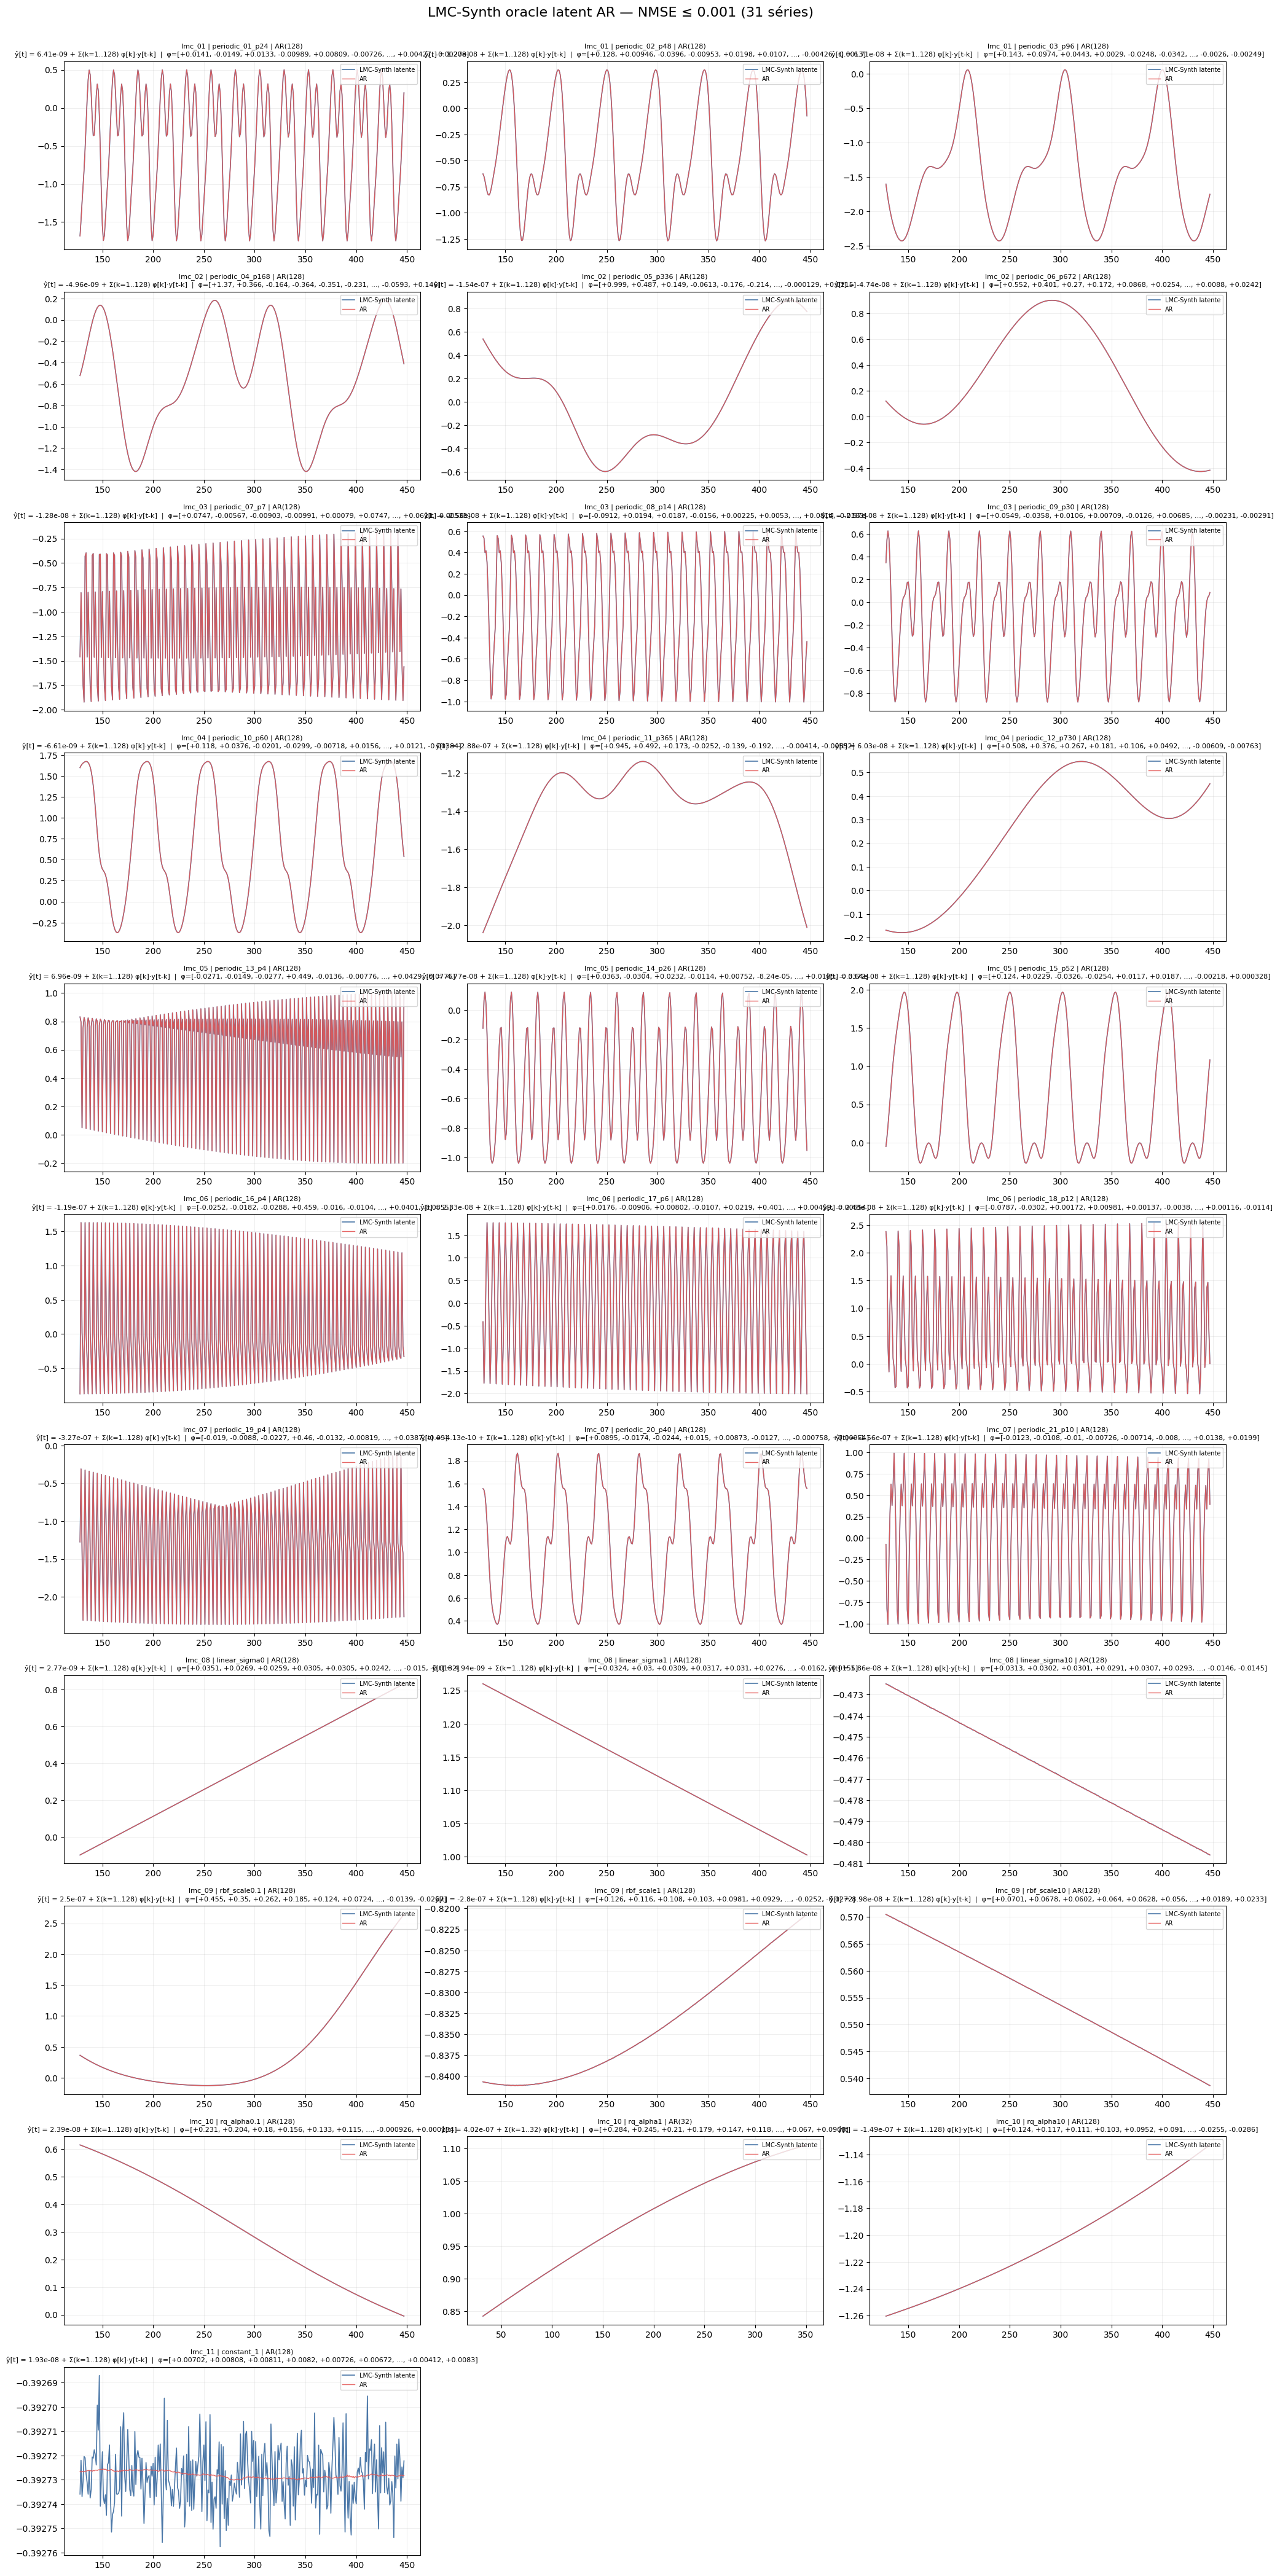

In [4]:
successful_cases = [case for case in plot_cases if case['covered']]
plot_cases_in_one_figure(successful_cases, f'LMC-Synth oracle latent AR — NMSE ≤ {NMSE_THRESHOLD:g} ({len(successful_cases)} séries)')

## Todas as séries que não deram certo por NMSE — uma célula

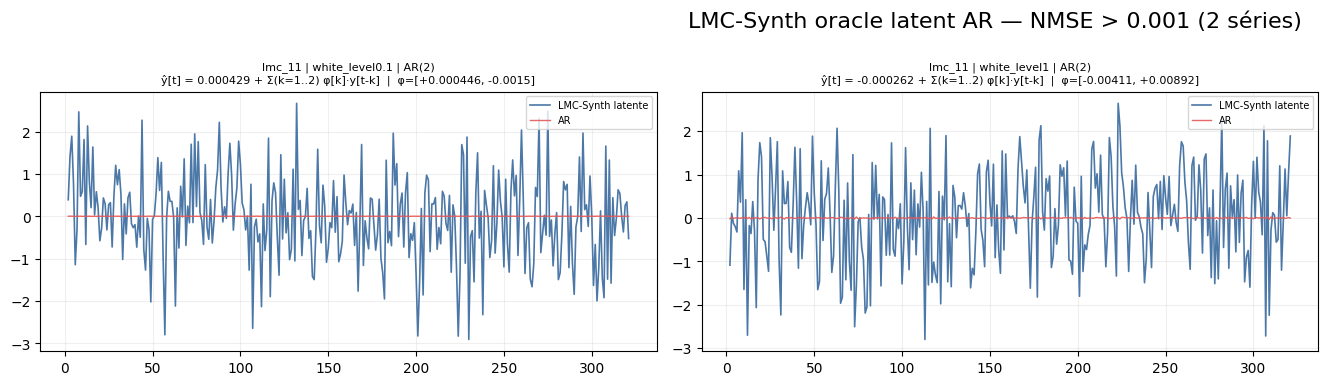

In [5]:
failed_cases = [case for case in plot_cases if not case['covered']]
plot_cases_in_one_figure(failed_cases, f'LMC-Synth oracle latent AR — NMSE > {NMSE_THRESHOLD:g} ({len(failed_cases)} séries)')

## COMPLETE EXPERIMENT RECORD — registro canônico deste notebook

In [6]:
record = {
    'experiment_id': 'timepfn_lmc_oracle_latent_ar_prediction_results',
    'status': 'executed',
    'research_question': 'How do representative TimePFN LMC-Synth latent trajectories compare visually with their selected one-step AR predictions?',
    'hypothesis': 'The minimum-NMSE AR model separates visually accurate and inaccurate latent one-step forecasts at an NMSE threshold of 0.001.',
    'configuration': {
        'source_experiment': str(SOURCE_NOTEBOOK.relative_to(PROJECT_ROOT)),
        'evaluation_mode': 'oracle_latent_AR only', 'plot_points': PLOT_POINTS,
        'model_selection': 'minimum individual forecast_nmse for each latent series across all canonical AR orders',
        'success_rule': 'minimum forecast_nmse <= 0.001',
        'nmse_threshold': NMSE_THRESHOLD,
        'comparison': 'one-step-ahead prediction on test trajectory index 0 for each latent',
        'classification_explanation': 'one Markdown cell explains the NMSE threshold; plots contain no repeated metric footer',
        'canonical_configuration': canonical_record['configuration'],
    },
    'provenance': {
        'source_sha256': hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest(),
        'python': sys.version, 'platform': platform.platform(),
        'packages': {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scipy', 'scikit-learn']},
    },
    'seed_usage': canonical_record['seed_usage'],
    'metrics': {
        'mechanism_count': len(LMC_MECHANISMS), 'latent_series_count': len(plot_cases),
        'nmse_pass_series_count': len(successful_cases), 'nmse_fail_series_count': len(failed_cases),
        'selected_models': selected.to_dict(orient='records'),
    },
    'scientific_summary': f'{len(successful_cases)}/{len(plot_cases)} latent series achieved minimum forecast NMSE <= {NMSE_THRESHOLD:g}; {len(failed_cases)} remained above the threshold. Every latent uses its own minimum-NMSE AR order.',
    'reproduction_command': r'.\.venv\Scripts\python.exe -m nbconvert --to notebook --execute experiments\autoregressive_process_coverage\02_timepfn_lmc_ar_prediction_results.ipynb --inplace --ExecutePreprocessor.timeout=3600',
}
print('COMPLETE EXPERIMENT RECORD')
print(json.dumps(record, indent=2, ensure_ascii=False))

COMPLETE EXPERIMENT RECORD
{
  "experiment_id": "timepfn_lmc_oracle_latent_ar_prediction_results",
  "status": "executed",
  "research_question": "How do representative TimePFN LMC-Synth latent trajectories compare visually with their selected one-step AR predictions?",
  "hypothesis": "The minimum-NMSE AR model separates visually accurate and inaccurate latent one-step forecasts at an NMSE threshold of 0.001.",
  "configuration": {
    "source_experiment": "experiments\\autoregressive_process_coverage\\AR\\02_timepfn_lmc_ar_var_coverage.ipynb",
    "evaluation_mode": "oracle_latent_AR only",
    "plot_points": 320,
    "model_selection": "minimum individual forecast_nmse for each latent series across all canonical AR orders",
    "success_rule": "minimum forecast_nmse <= 0.001",
    "nmse_threshold": 0.001,
    "comparison": "one-step-ahead prediction on test trajectory index 0 for each latent",
    "classification_explanation": "one Markdown cell explains the NMSE threshold; plots co